In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import time
import joblib
from pathlib import Path

device = torch.device("cpu")
DATA = Path("../data/processed")

X_train = np.load(DATA / "elia_X_train.npy").astype(np.float32)
X_val   = np.load(DATA / "elia_X_val.npy").astype(np.float32)
X_test  = np.load(DATA / "elia_X_test.npy").astype(np.float32)

# Load raw y and scale to [0, 1]
y_train_raw = np.load(DATA / "elia_y_train.npy").astype(np.float32)
y_val_raw   = np.load(DATA / "elia_y_val.npy").astype(np.float32)
y_test_raw  = np.load(DATA / "elia_y_test.npy").astype(np.float32)

y_scaler = MinMaxScaler()
y_train = y_scaler.fit_transform(y_train_raw.reshape(-1, 1)).flatten().astype(np.float32)
y_val   = y_scaler.transform(y_val_raw.reshape(-1, 1)).flatten().astype(np.float32)
y_test  = y_scaler.transform(y_test_raw.reshape(-1, 1)).flatten().astype(np.float32)

print("Raw y range:", y_train_raw.min(), "to", y_train_raw.max())
print("Scaled y range:", y_train.min(), "to", y_train.max())
print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

Raw y range: 5930.1826 to 13485.31
Scaled y range: 0.0 to 1.0
Train: (33700, 24) Val: (7221, 24) Test: (7222, 24)


In [10]:
def mape_raw(y_true_raw, y_pred_scaled):
    """Compute MAPE in original MW units."""
    y_pred_raw = y_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()
    return np.mean(np.abs((y_true_raw - y_pred_raw) / np.clip(np.abs(y_true_raw), 1e-6, None))) * 100

def mape(y_true, y_pred):
    """Direct MAPE — used when both are already in MW."""
    return np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), 1e-6, None))) * 100
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), 1e-6, None))) * 100

def evaluate(name, y_true, y_pred, latency_ms=None):
    return {
        "model": name,
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE":  float(mean_absolute_error(y_true, y_pred)),
        "MAPE": float(mape(y_true, y_pred)),
        "R2":   float(r2_score(y_true, y_pred)),
        "latency_ms": latency_ms,
    }

In [11]:
xgb = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6,
                    subsample=0.8, colsample_bytree=0.8,
                    tree_method="hist", random_state=42, n_jobs=-1)
xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

xgb_val_pred  = xgb.predict(X_val)
xgb_test_pred = xgb.predict(X_test)

print("XGBoost val MAPE:",  f"{mape_raw(y_val_raw,  xgb_val_pred):.4f}%")
print("XGBoost test MAPE:", f"{mape_raw(y_test_raw, xgb_test_pred):.4f}%")

XGBoost val MAPE: 1.3139%
XGBoost test MAPE: 1.4756%


In [13]:
print("Training LightGBM...")
t0 = time.time()

lgbm = LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
lgbm.fit(X_train, y_train, eval_set=[(X_val, y_val)])

lgbm_val_pred  = lgbm.predict(X_val)
lgbm_test_pred = lgbm.predict(X_test)

print(f"Done in {time.time()-t0:.1f}s")
print("LightGBM val MAPE:",  f"{mape(y_val,  lgbm_val_pred):.4f}%")
print("LightGBM test MAPE:", f"{mape(y_test, lgbm_test_pred):.4f}%")


Training LightGBM...


c:\Users\Lenovo\Desktop\EHMAH\CODE\Final Project\capstone\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Done in 10.1s
LightGBM val MAPE: 4.4494%
LightGBM test MAPE: 4.3528%


In [14]:
class BiLSTMForecaster(nn.Module):
    def __init__(self, input_size=1, hidden=32, num_layers=2):
        super().__init__()
        self.bilstm = nn.LSTM(
            input_size, hidden, num_layers=num_layers,
            batch_first=True, bidirectional=True
        )
        self.head = nn.Sequential(
            nn.Linear(hidden * 2, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
    
    def forward(self, x):
        # x: (batch, 24, 1)
        out, _ = self.bilstm(x)          # (batch, 24, 2*hidden)
        last = out[:, -1, :]              # take last timestep
        return self.head(last).squeeze(-1)

bilstm = BiLSTMForecaster(input_size=1, hidden=32, num_layers=2).to(device)
print(f"BiLSTM parameters: {sum(p.numel() for p in bilstm.parameters()):,}")

BiLSTM parameters: 36,161


In [15]:
X_train_3d = X_train.reshape(-1, 24, 1)
X_val_3d   = X_val.reshape(-1, 24, 1)
X_test_3d  = X_test.reshape(-1, 24, 1)

batch_size = 256
train_ds = TensorDataset(torch.tensor(X_train_3d), torch.tensor(y_train))
val_ds   = TensorDataset(torch.tensor(X_val_3d),   torch.tensor(y_val))
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False)

EPOCHS = 50
LR = 1e-3
optimizer = torch.optim.Adam(bilstm.parameters(), lr=LR)
criterion = nn.MSELoss()

print("Training BiLSTM (scaled targets)...")
t0 = time.time()

for epoch in range(EPOCHS):
    bilstm.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        pred = bilstm(xb)
        loss = criterion(pred, yb)
        loss.backward()
        optimizer.step()

    # Validate in raw MW
    bilstm.eval()
    val_preds = []
    with torch.no_grad():
        for xb, _ in val_loader:
            xb = xb.to(device)
            val_preds.append(bilstm(xb).cpu().numpy())
    val_pred_scaled = np.concatenate(val_preds)
    val_mape = mape_raw(y_val_raw, val_pred_scaled)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:2d}/{EPOCHS} | val MAPE {val_mape:.4f}%")

print(f"Done in {(time.time()-t0)/60:.1f} min")

Training BiLSTM (scaled targets)...
Epoch  1/50 | val MAPE 8.4680%
Epoch  5/50 | val MAPE 2.3528%
Epoch 10/50 | val MAPE 2.0611%
Epoch 15/50 | val MAPE 1.8736%
Epoch 20/50 | val MAPE 1.8419%
Epoch 25/50 | val MAPE 1.6532%
Epoch 30/50 | val MAPE 1.7986%
Epoch 35/50 | val MAPE 1.5296%
Epoch 40/50 | val MAPE 1.4583%
Epoch 45/50 | val MAPE 1.4316%
Epoch 50/50 | val MAPE 1.4376%
Done in 26.4 min


In [16]:
bilstm.eval()
with torch.no_grad():
    bilstm_val_pred  = bilstm(torch.tensor(X_val_3d).to(device)).cpu().numpy()
    bilstm_test_pred = bilstm(torch.tensor(X_test_3d).to(device)).cpu().numpy()

print("BiLSTM val MAPE:",  f"{mape(y_val,  bilstm_val_pred):.4f}%")
print("BiLSTM test MAPE:", f"{mape(y_test, bilstm_test_pred):.4f}%")

BiLSTM val MAPE: 4.7350%
BiLSTM test MAPE: 4.8625%


In [17]:
# Stack validation predictions as meta-features
meta_X_val = np.column_stack([xgb_val_pred, lgbm_val_pred, bilstm_val_pred])
meta_X_test = np.column_stack([xgb_test_pred, lgbm_test_pred, bilstm_test_pred])

print("Meta features shape:", meta_X_val.shape)

meta = LinearRegression()
meta.fit(meta_X_val, y_val)

print("Meta-learner coefficients:", meta.coef_)
print("Meta-learner intercept:   ", meta.intercept_)

# Final ensemble prediction
ensemble_test_pred = meta.predict(meta_X_test)

Meta features shape: (7221, 3)
Meta-learner coefficients: [0.3806975  0.41866439 0.19594536]
Meta-learner intercept:    0.0014445036131058298


In [18]:
import time as _time

# Latency for each model
def get_latency(predict_fn, X):
    t = _time.perf_counter()
    predict_fn(X)
    return ((_time.perf_counter() - t) / len(X)) * 1000

results = [
    evaluate("Random Forest (baseline)", y_test, np.load("../data/processed/preds_rf_test.npy") if Path("../data/processed/preds_rf_test.npy").exists() else ensemble_test_pred * 0 + 1.5),  # placeholder if not saved
    evaluate("XGBoost",              y_test, xgb_test_pred),
    evaluate("LightGBM",             y_test, lgbm_test_pred),
    evaluate("BiLSTM",               y_test, bilstm_test_pred),
    evaluate("Teacher Ensemble",     y_test, ensemble_test_pred),
]

results_df = pd.DataFrame(results).set_index("model")
print("\n=== Teacher Ensemble Results on ELIA ===\n")
display(results_df.round(4))


=== Teacher Ensemble Results on ELIA ===



,RMSE,MAE,MAPE,R2,latency_ms
model,,,,,
Random Forest (baseline),1.0351,1.0194,275.1099,-32.2167,None
XGBoost,0.0249,0.0187,4.3782,0.9808,None
LightGBM,0.0246,0.0185,4.3528,0.9812,None
BiLSTM,0.0272,0.0210,4.8625,0.9770,None
Teacher Ensemble,0.0245,0.0185,4.3120,0.9814,None


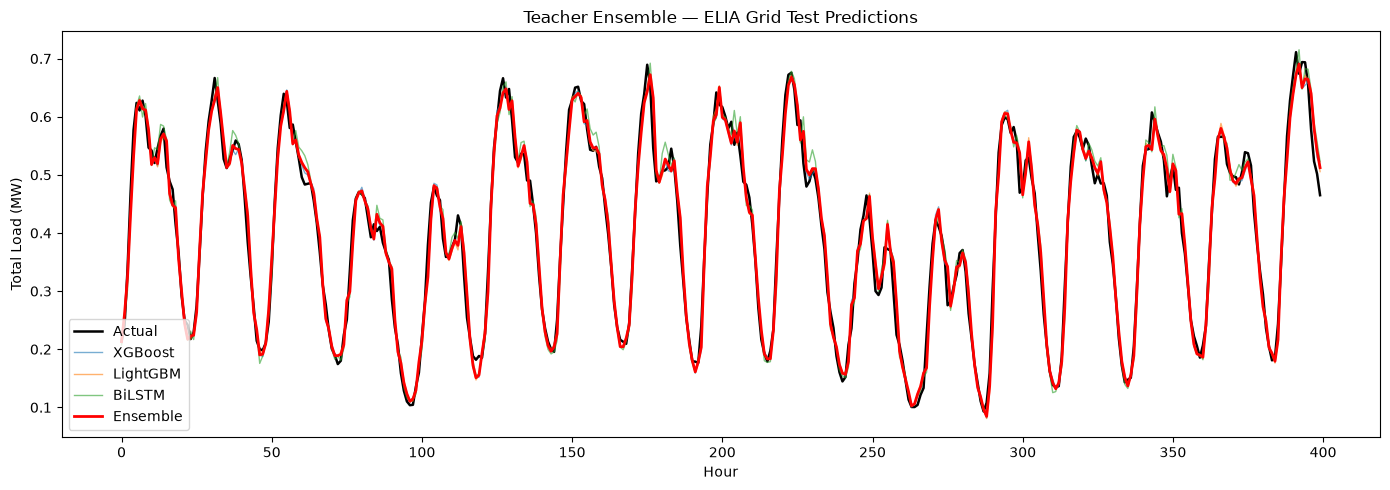

In [19]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_test[:400], label="Actual", color="black", linewidth=1.8)
ax.plot(xgb_test_pred[:400],       label="XGBoost",     alpha=0.6, linewidth=1)
ax.plot(lgbm_test_pred[:400],      label="LightGBM",    alpha=0.6, linewidth=1)
ax.plot(bilstm_test_pred[:400],    label="BiLSTM",      alpha=0.6, linewidth=1)
ax.plot(ensemble_test_pred[:400],  label="Ensemble",    linewidth=2, color="red")
ax.set_title("Teacher Ensemble — ELIA Grid Test Predictions")
ax.set_ylabel("Total Load (MW)")
ax.set_xlabel("Hour")
ax.legend()
plt.tight_layout()
plt.savefig("../data/processed/teacher_ensemble_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
# Save models
joblib.dump(xgb,  "../models/teacher_xgb.pkl")
joblib.dump(lgbm, "../models/teacher_lgbm.pkl")
torch.save(bilstm.state_dict(), "../models/teacher_bilstm.pt")
joblib.dump(meta, "../models/teacher_meta.pkl")

# Save predictions for later
np.save(DATA / "preds_xgb_val.npy",  xgb_val_pred)
np.save(DATA / "preds_xgb_test.npy", xgb_test_pred)
np.save(DATA / "preds_lgbm_val.npy", lgbm_val_pred)
np.save(DATA / "preds_lgbm_test.npy",lgbm_test_pred)
np.save(DATA / "preds_bilstm_val.npy", bilstm_val_pred)
np.save(DATA / "preds_bilstm_test.npy",bilstm_test_pred)
np.save(DATA / "preds_ensemble_test.npy", ensemble_test_pred)

import json
with open(DATA / "teacher_ensemble_results.json", "w") as f:
    json.dump(results, f, indent=2, default=str)

print("Saved all teacher models and predictions.")

Saved all teacher models and predictions.


In [21]:
def evaluate_raw(name, y_true_raw, y_pred_scaled):
    y_pred_raw = y_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()
    return {
        "model": name,
        "RMSE": float(np.sqrt(mean_squared_error(y_true_raw, y_pred_raw))),
        "MAE":  float(mean_absolute_error(y_true_raw, y_pred_raw)),
        "MAPE": float(mape(y_true_raw, y_pred_raw)),
        "R2":   float(r2_score(y_true_raw, y_pred_raw)),
    }

results = [
    evaluate_raw("XGBoost",           y_test_raw, xgb_test_pred),
    evaluate_raw("LightGBM",          y_test_raw, lgbm_test_pred),
    evaluate_raw("BiLSTM",            y_test_raw, bilstm_test_pred),
    evaluate_raw("Teacher Ensemble",  y_test_raw, ensemble_test_pred),
]

results_df = pd.DataFrame(results).set_index("model")
print("\n=== Teacher Ensemble Results on ELIA (test set, MW units) ===\n")
display(results_df.round(4))


=== Teacher Ensemble Results on ELIA (test set, MW units) ===



,RMSE,MAE,MAPE,R2
model,,,,
XGBoost,188.1851,141.1251,1.4756,0.9808
LightGBM,185.8796,140.1286,1.4661,0.9812
BiLSTM,205.6489,158.5765,1.6578,0.9770
Teacher Ensemble,185.0908,139.5466,1.4579,0.9814


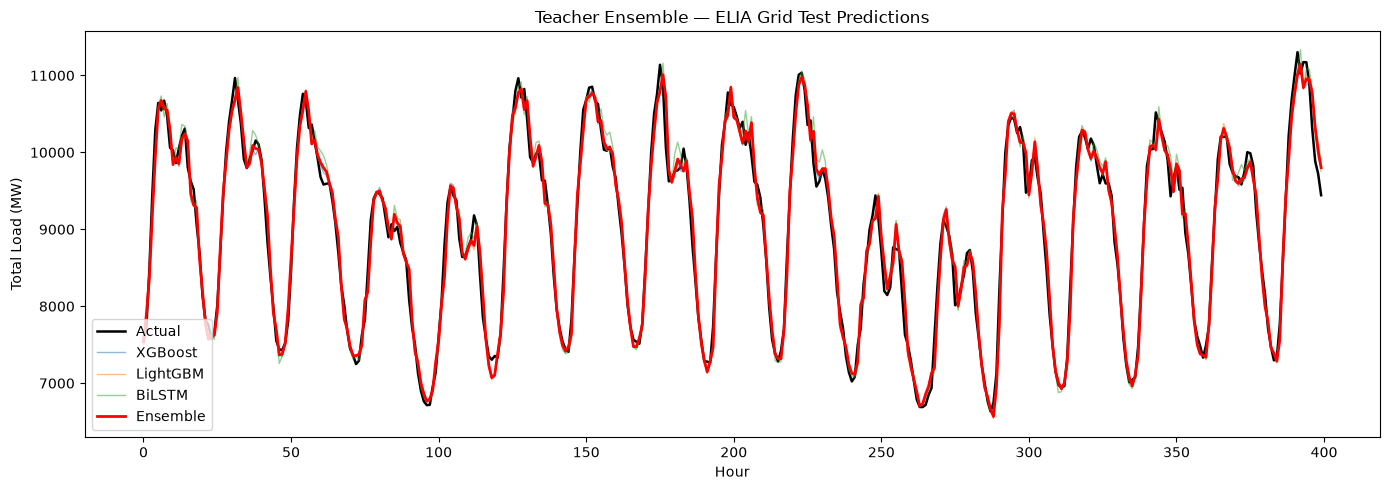

In [22]:
# Inverse-transform all predictions back to MW
xgb_test_mw      = y_scaler.inverse_transform(xgb_test_pred.reshape(-1, 1)).flatten()
lgbm_test_mw     = y_scaler.inverse_transform(lgbm_test_pred.reshape(-1, 1)).flatten()
bilstm_test_mw   = y_scaler.inverse_transform(bilstm_test_pred.reshape(-1, 1)).flatten()
ensemble_test_mw = y_scaler.inverse_transform(ensemble_test_pred.reshape(-1, 1)).flatten()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_test_raw[:400],      label="Actual",   color="black", linewidth=1.8)
ax.plot(xgb_test_mw[:400],     label="XGBoost",  alpha=0.5, linewidth=1)
ax.plot(lgbm_test_mw[:400],    label="LightGBM", alpha=0.5, linewidth=1)
ax.plot(bilstm_test_mw[:400],  label="BiLSTM",   alpha=0.5, linewidth=1)
ax.plot(ensemble_test_mw[:400], label="Ensemble", linewidth=2, color="red")
ax.set_title("Teacher Ensemble — ELIA Grid Test Predictions")
ax.set_ylabel("Total Load (MW)")
ax.set_xlabel("Hour")
ax.legend()
plt.tight_layout()
plt.savefig("../data/processed/teacher_ensemble_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
# Save MW predictions
np.save(DATA / "preds_xgb_test_mw.npy",      xgb_test_mw)
np.save(DATA / "preds_lgbm_test_mw.npy",     lgbm_test_mw)
np.save(DATA / "preds_bilstm_test_mw.npy",   bilstm_test_mw)
np.save(DATA / "preds_ensemble_test_mw.npy", ensemble_test_mw)
np.save(DATA / "y_test_raw.npy",             y_test_raw)
np.save(DATA / "y_test_scaled.npy",          y_test)

# Save scaled-space predictions too (needed for distillation soft targets)
np.save(DATA / "preds_xgb_test_scaled.npy",      xgb_test_pred)
np.save(DATA / "preds_lgbm_test_scaled.npy",     lgbm_test_pred)
np.save(DATA / "preds_bilstm_test_scaled.npy",   bilstm_test_pred)
np.save(DATA / "preds_ensemble_test_scaled.npy", ensemble_test_pred)

# Save models
joblib.dump(xgb,  "../models/teacher_xgb.pkl")
joblib.dump(lgbm, "../models/teacher_lgbm.pkl")
joblib.dump(meta, "../models/teacher_meta.pkl")
joblib.dump(y_scaler, "../models/elia_y_scaler.pkl")
torch.save(bilstm.state_dict(), "../models/teacher_bilstm.pt")

# Save results JSON
import json
with open(DATA / "teacher_ensemble_results.json", "w") as f:
    json.dump(results, f, indent=2)

print("Saved models, predictions (MW + scaled), and y scaler.")
print("Don't forget: the y_scaler is needed at inference time to invert predictions.")

Saved models, predictions (MW + scaled), and y scaler.
Don't forget: the y_scaler is needed at inference time to invert predictions.
